# Figure 2, Panel F

Barplots of ridge regression coefficients for the top 15 features associated with either BAF-dependence (i.e, most negative coeffs) and BAF-independence (most positive coeffs). Accompanying heatmaps show tau scores for tissue specificity for each feature. 

*Output file: PanelF.pdf*

# Setup

In [1]:
library(tidyverse)
library(RColorBrewer)
library(patchwork)
library(here)
here::i_am("figures/Figure2/Panel_F/PanelF.ipynb")
here()
theme_set(theme_bw() + theme(panel.grid=element_blank(), axis.text=element_text(size=10)))

sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure2/Panel_F

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



[1] "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"

R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2         patchwork_1.3.0    RColorBrewer_1.1-3 lubridate_1.9.4   
 [5] forcats_1.0.0      stringr_1.5.1      dplyr_1.1.4        purrr_1.0.2       
 [9] readr_2.1.5        tidyr_1.3.1        tibble_3.2.1       ggplot2_3.5.2     
[13] tidyverse_2.0.0   

loaded via a namespace (an

# Load data

In [2]:
#load data
#feature importance metrics (enhancer only model, 10µM BAFinh @ 6h)
feature_importances <- read.delim(
  here(
    "inputs", "ReModEx", "GM12878", "enh_only",
    "dose_10uM", "feature_importance.csv"
  ),
  sep = ","
)

#Tau tissue-specificity indexes
tau <- read.delim(
  here(
    "figures", "Figure2", "tau",
    "GENCODE_GTex_Tau.tsv"
  )
) %>%
  rename("feature" = "gene_name")

# Generate plots

Joining with `by = join_by(feature)`


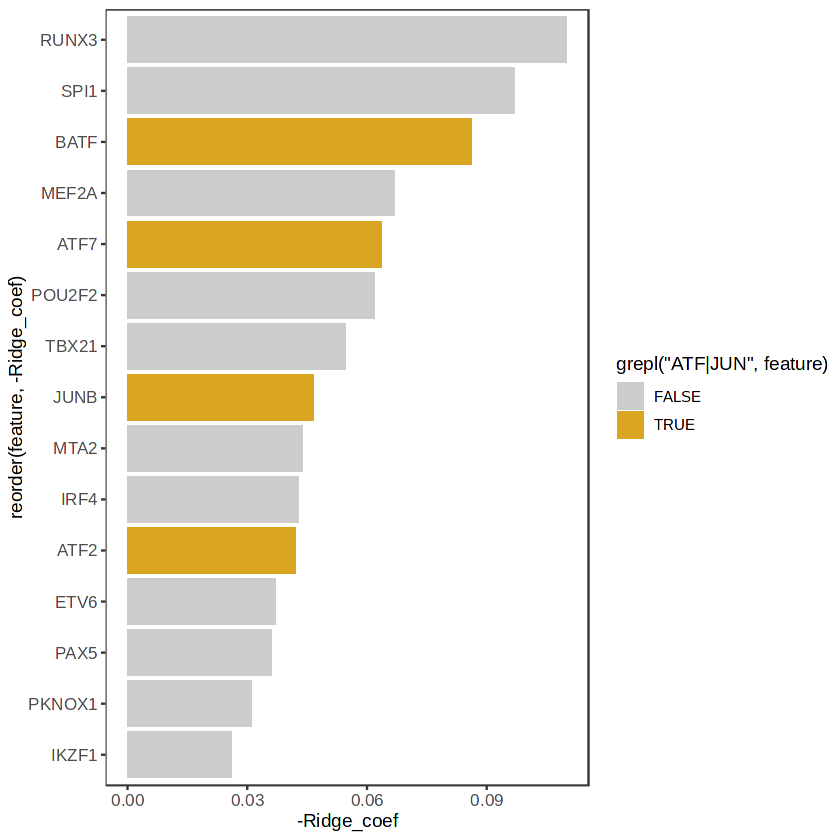

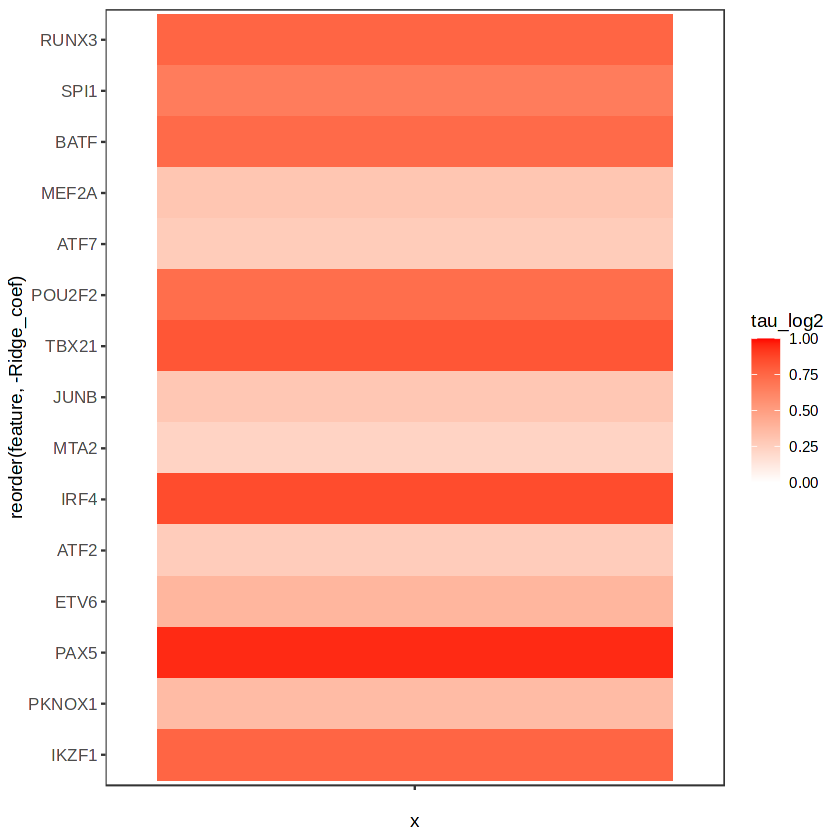

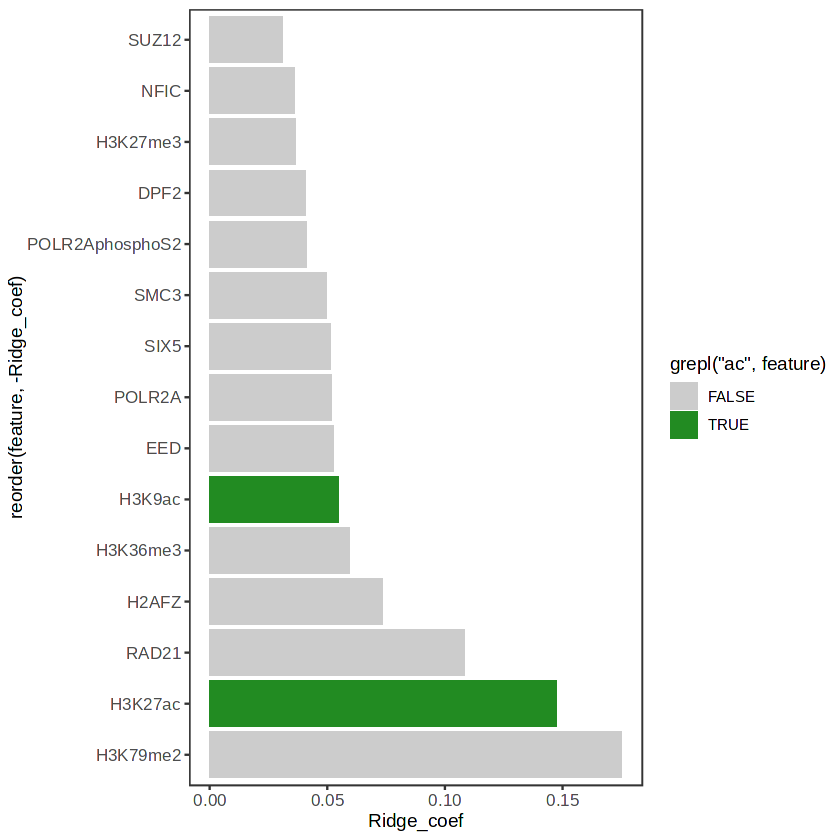

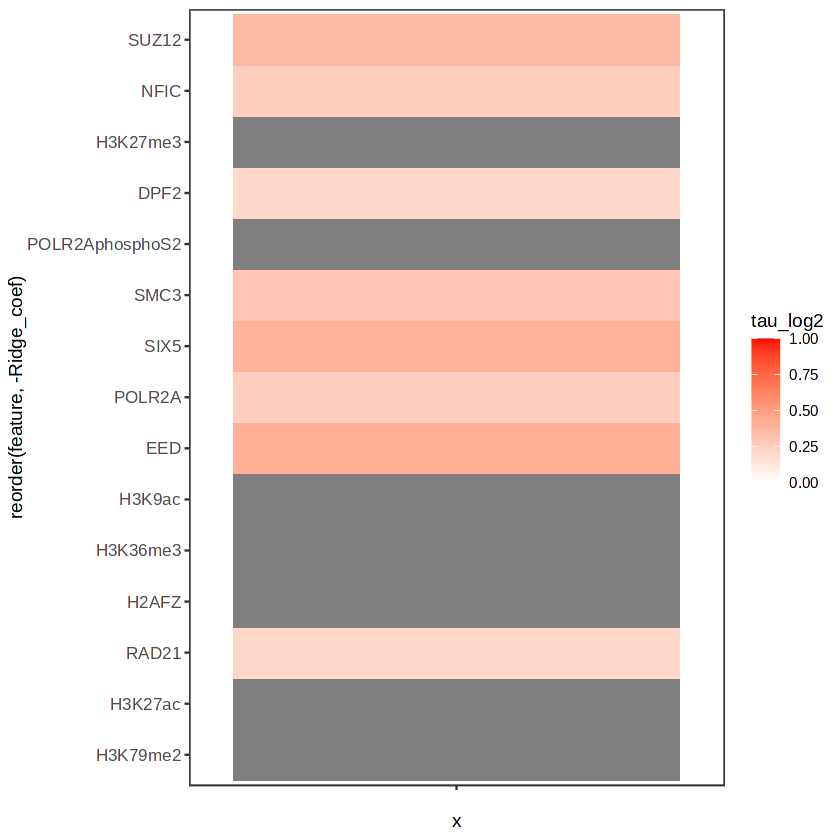

In [3]:
# add tau indices to feature importance data frame
feat_w_tau <- left_join(feature_importances, tau)

#plot ridge coefs for top BAF-dep features, with fill representing AP-1 and non-AP-1 features
plot_top15_dep <- 
    feat_w_tau %>% 
    arrange(Ridge_coef) %>% 
    head(15) %>%
    ggplot(aes(y=reorder(feature, -Ridge_coef), x=-Ridge_coef)) +
    geom_col(aes(fill=grepl("ATF|JUN", feature))) +
    scale_fill_manual(values=c("#cccccc", "goldenrod"))
plot_top15_dep

#plot tau indices for same features
plot_top15_dep_tau <- 
    feat_w_tau %>% 
    arrange(Ridge_coef) %>% 
    head(15) %>%
    ggplot(aes(y=reorder(feature, -Ridge_coef), x="", fill=tau_log2)) +
    geom_tile() +
    scale_fill_gradient2(low="white", high="red", limits=c(0,1))
plot_top15_dep_tau

#as above but for BAF-indep features; here, fill highlights active chromatin marks H3K27ac/H3K9ac
plot_top15_indep <- 
    feat_w_tau %>% 
    arrange(desc(Ridge_coef)) %>% 
    head(15) %>%
    ggplot(aes(y=reorder(feature, -Ridge_coef), x=Ridge_coef)) +
    geom_col(aes(fill=grepl("ac", feature))) +
    scale_fill_manual(values=c("#cccccc", "forestgreen"))
plot_top15_indep

plot_top15_indep_tau <- 
    feat_w_tau %>% 
    arrange(desc(Ridge_coef)) %>% 
    head(15) %>%
    ggplot(aes(y=reorder(feature, -Ridge_coef), x="", fill=tau_log2)) +
    geom_tile() +
    scale_fill_gradient2(low="white", high="red", limits=c(0,1))
plot_top15_indep_tau

# Assemble figure panel

Saving 7 x 7 in image


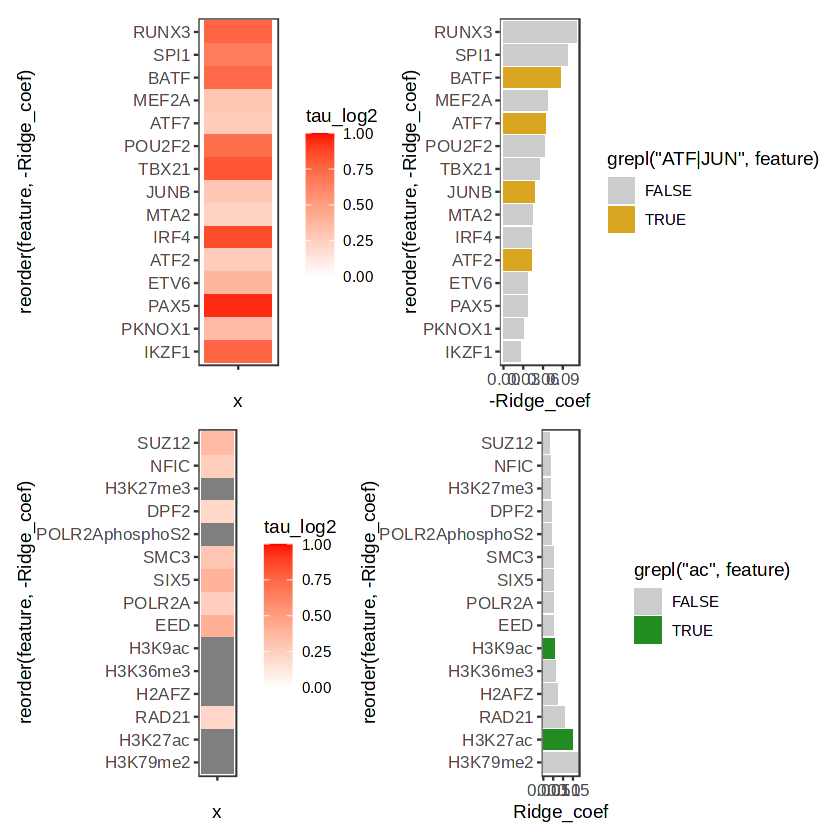

In [19]:
((plot_top15_dep_tau | plot_top15_dep)) / ((plot_top15_indep_tau + plot_top15_indep))
ggsave("PanelF.pdf")